OPCIÓN 1 (MultinomialNB)


In [1]:
#descargar los datos y visualizarlos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Proyecto EOI/fake reviews dataset.csv', engine='python', on_bad_lines='skip')# Cargar datos
 # Mostrar las primeras filas y columnas

# Mostrar información técnica (tipos de datos, nulos)
print("\nInformación del DataFrame:")
df.info()
print(df.head())

Mounted at /content/drive

Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40432 non-null  object 
 3   text_     40432 non-null  object 
dtypes: float64(1), object(3)
memory usage: 1.2+ MB
             category  rating label  \
0  Home_and_Kitchen_5     5.0    CG   
1  Home_and_Kitchen_5     5.0    CG   
2  Home_and_Kitchen_5     5.0    CG   
3  Home_and_Kitchen_5     1.0    CG   
4  Home_and_Kitchen_5     5.0    CG   

                                               text_  
0  Love this!  Well made, sturdy, and very comfor...  
1  love it, a great upgrade from the original.  I...  
2  This pillow saved my back. I love the look and...  
3  Missing information on how to use it, but it i...  
4  Very nice set. Good quality. We have ha

In [2]:
#Mapear valores categóricos a números: crear diccionario y modificar columna
talla_mapping = {'OR':0, 'CG':1}
df['label'] = df['label'].map(talla_mapping)

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['category'] = le.fit_transform(df['category'])


# Mostrar información técnica (tipos de datos, nulos)
print("\nInformación del DataFrame:")
#borrar datos faltantes
df.dropna(inplace=True)
df.info()
print(df.head())


Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  int64  
 1   rating    40432 non-null  float64
 2   label     40432 non-null  int64  
 3   text_     40432 non-null  object 
dtypes: float64(1), int64(2), object(1)
memory usage: 1.2+ MB
   category  rating  label                                              text_
0         3     5.0      1  Love this!  Well made, sturdy, and very comfor...
1         3     5.0      1  love it, a great upgrade from the original.  I...
2         3     5.0      1  This pillow saved my back. I love the look and...
3         3     1.0      1  Missing information on how to use it, but it i...
4         3     5.0      1  Very nice set. Good quality. We have had the s...



--- Reporte de Clasificación ---
               precision    recall  f1-score   support

   Humano (0)       0.88      0.89      0.88      4044
Ordenador (1)       0.89      0.88      0.88      4043

     accuracy                           0.88      8087
    macro avg       0.88      0.88      0.88      8087
 weighted avg       0.88      0.88      0.88      8087

Precisión del modelo: 0.88


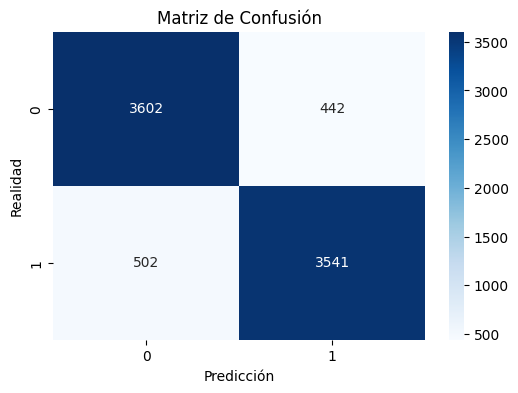

In [ ]:
#Primero VECTORIZACIÓN: Convertir palabras a números
# TfidfVectorizer convierte el texto en una matriz numérica dando peso a las palabras importantes.
# stop_words='english' elimina palabras comunes como "the", "is", etc. (si los datos están en inglés).
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

X = df['text_']
y = df['label']

vectorizer = TfidfVectorizer(stop_words='english', max_features=15000, ngram_range=(1, 2))
X_vectorizado = vectorizer.fit_transform(X)


X_train, X_test, y_train, y_test = train_test_split(X_vectorizado, y, test_size=0.2, random_state=42, stratify=y)
modelo = MultinomialNB(alpha=0.5)#mejor este alpha que alpha=1.0
modelo.fit(X_train, y_train)

# 5. EVALUACIÓN
y_pred = modelo.predict(X_test)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred, target_names=['Humano (0)', 'Ordenador (1)']))

print(f"Precisión del modelo: {accuracy_score(y_test, y_pred):.2f}")
# Mostrar matriz de confusión visual
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, auc
# Probabilidades para la clase fake (label = 1)
y_proba = modelo.predict_proba(X_test)[:, 1]

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Área bajo la curva
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fake Review Detection')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

X = df['text_']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
pipeline_nb = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        ngram_range=(1,2), max_features=15000
    )),
    ('nb', MultinomialNB())
])

param_grid_nb = {
    'nb__alpha': [0.01, 0.1, 0.5, 1.0]
}

grid_nb = GridSearchCV(
    pipeline_nb,
    param_grid_nb,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_nb.fit(X_train, y_train)

best_nb = grid_nb.best_estimator_


--- Reporte de Clasificación ---
               precision    recall  f1-score   support

   Humano (0)       0.88      0.89      0.89      4044
Ordenador (1)       0.89      0.88      0.88      4043

     accuracy                           0.88      8087
    macro avg       0.88      0.88      0.88      8087
 weighted avg       0.88      0.88      0.88      8087

Precisión del modelo: 0.88


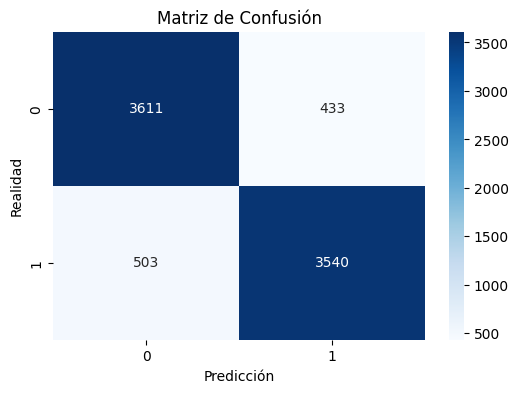

In [ ]:
y_pred =best_nb.predict(X_test)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred, target_names=['Humano (0)', 'Ordenador (1)']))

print(f"Precisión del modelo: {accuracy_score(y_test, y_pred):.2f}")
# Mostrar matriz de confusión visual
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

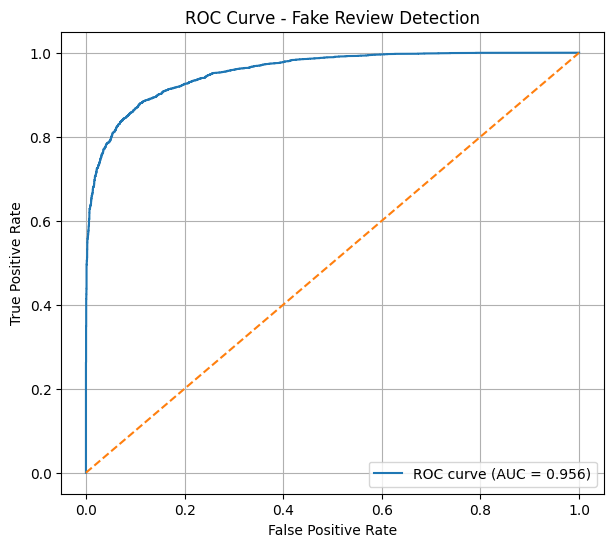

In [ ]:
from sklearn.metrics import roc_curve, auc
# Probabilidades para la clase fake (label = 1)
y_proba = best_nb.predict_proba(X_test)[:, 1]

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

# Área bajo la curva
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fake Review Detection')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
# 1. OBTENER PROBABILIDADES
probs = modelo.predict_proba(X_test)

# 2. EXTRAER SOLO LA PROBABILIDAD DE QUE SEA FAKE (Columna 1)
probabilidad_fake = probs[:, 1]

# 3. VER ALGUNOS EJEMPLOS
print("--- Probabilidades de ser Fake ---")
for i in range(5):
    realidad = "Fake" if y_test.iloc[i] == 1 else "Real"
    p_fake = probabilidad_fake[i]
    print(f"Realidad: {realidad} | Probabilidad calculada de ser Fake: {p_fake:.2%} ")

--- Probabilidades de ser Fake ---
Realidad: Fake | Probabilidad calculada de ser Fake: 92.97% 
Realidad: Fake | Probabilidad calculada de ser Fake: 91.68% 
Realidad: Real | Probabilidad calculada de ser Fake: 25.15% 
Realidad: Fake | Probabilidad calculada de ser Fake: 72.65% 
Realidad: Real | Probabilidad calculada de ser Fake: 16.77% 


OPCIÓN 2 (Regresión Logística)

Entrenando modelo...

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      4044
           1       0.88      0.87      0.88      4043

    accuracy                           0.88      8087
   macro avg       0.88      0.88      0.88      8087
weighted avg       0.88      0.88      0.88      8087


--- Matriz de Confusión ---
[[3578  466]
 [ 536 3507]]


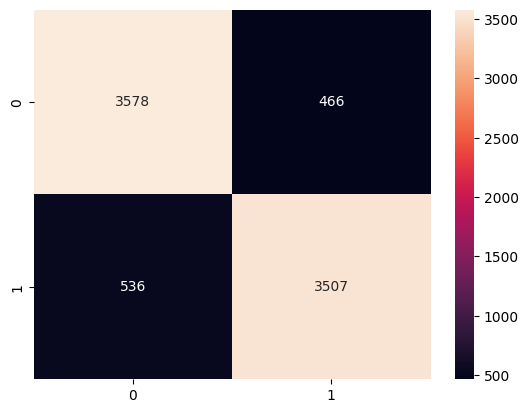

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline

X = df['text_']
y = df['label']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y) #mejora con stratify=y

# Pipeline (Tubería):Esto hace la vectorización y el entrenamiento en un solo paso
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_df=0.7,ngram_range=(1, 2))), # texto a números
    ('clf', LogisticRegression(max_iter=300, class_weight='balanced'))# mejora con class_weight
])

# 4. Entrenar
print("Entrenando modelo...")
pipeline.fit(X_train, y_train)

# 5. Evaluar
predictions = pipeline.predict(X_test)

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
print(confusion_matrix(y_test, predictions))

import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='d')
plt.show()



In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
X = df['text_']
y = df['label']

vectorizer=TfidfVectorizer(stop_words='english', max_df=0.7,ngram_range=(1, 2))
X_vectorizado = vectorizer.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_vectorizado, y, test_size=0.2, random_state=42,stratify=y) #mejora con stratify=y


# Definir modelo
logreg = LogisticRegression(max_iter=1000,class_weight='balanced')

# Hiperparámetros para ajustar
param_grid = {
    'C': [0.01, 0.1, 1, 10],       # regularización inversa
    'penalty': ['l2'],             # L2 regularization
    'solver': ['lbfgs']            # solver compatible
}

# GridSearchCV con validación cruzada
grid = GridSearchCV(logreg, param_grid, cv=5, scoring='roc_auc')
grid.fit(X_train, y_train)

# Mejor modelo
best_logreg = grid.best_estimator_

              precision    recall  f1-score   support

           0       0.88      0.93      0.91      4044
           1       0.93      0.88      0.90      4043

    accuracy                           0.91      8087
   macro avg       0.91      0.91      0.91      8087
weighted avg       0.91      0.91      0.91      8087

ROC-AUC: 0.9662745172873314


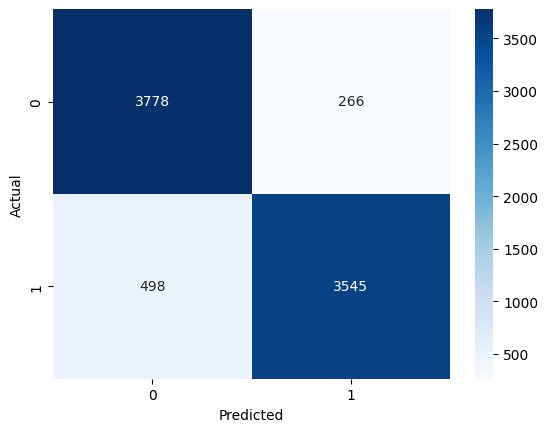

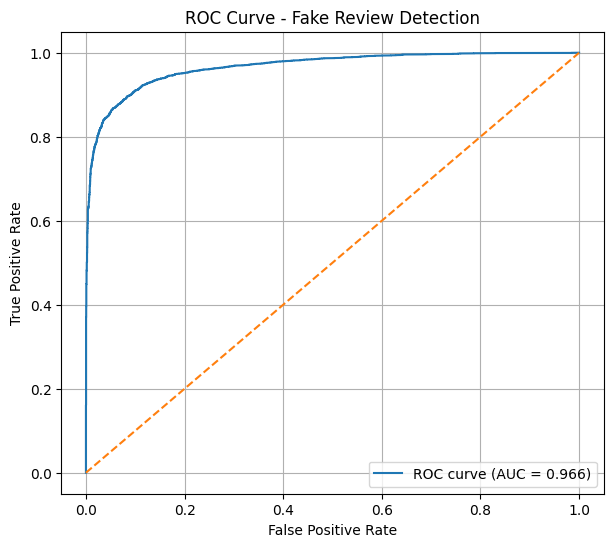

In [7]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
y_pred = best_logreg.predict(X_test)
y_prob = best_logreg.predict_proba(X_test)[:,1]

# Métricas
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
# Matriz de confusión
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Área bajo la curva
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fake Review Detection')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
for solver in ['liblinear', 'saga', 'lbfgs']:  #mejor lbfgs
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(
            stop_words='english',
            max_df=0.7,
            ngram_range=(1, 2)
        )),
        ('clf', LogisticRegression(
            solver=solver,
            max_iter=500,
            class_weight='balanced'
        ))
    ])

    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)

    print(f"\nSolver: {solver}")
    print(classification_report(y_test, preds))


Solver: liblinear
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      4044
           1       0.88      0.87      0.87      4043

    accuracy                           0.88      8087
   macro avg       0.88      0.88      0.88      8087
weighted avg       0.88      0.88      0.88      8087


Solver: saga
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      4044
           1       0.88      0.87      0.87      4043

    accuracy                           0.88      8087
   macro avg       0.88      0.88      0.88      8087
weighted avg       0.88      0.88      0.88      8087


Solver: lbfgs
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      4044
           1       0.88      0.87      0.88      4043

    accuracy                           0.88      8087
   macro avg       0.88      0.88      0.88      8087
weighted avg       0.88   

In [14]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 76.6 MB/s eta 0:00:00


Definimos la clase personalizada para integrar Word2Vec en Sklearn

In [15]:
from sklearn.base import BaseEstimator, TransformerMixin
from gensim.models import Word2Vec

#1. Definimos la clase personalizada para integrar Word2Vec en Sklearn
class Word2VecTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100, window=5, min_count=1, workers=4):
        self.vector_size = vector_size
        self.window = window
        self.min_count = min_count
        self.workers = workers
        self.model = None

    def fit(self, X, y=None):
        # Word2Vec necesita una lista de listas de palabras (tokens)
        # Aquí hacemos una tokenización simple (.split()).
        # Para mejores resultados usa nltk o gensim.utils.simple_preprocess
        sentences = [text.lower().split() for text in X]

        self.model = Word2Vec(sentences,
                              vector_size=self.vector_size,
                              window=self.window,
                              min_count=self.min_count,
                              workers=self.workers)
        return self

    def transform(self, X):
        # Convertimos cada texto en el promedio de sus vectores de palabras
        X_transformed = []
        for text in X:
            words = text.lower().split()
            # Filtramos palabras que estén en el vocabulario del modelo
            vectors = [self.model.wv[word] for word in words if word in self.model.wv]

            if vectors:
                # Promedio de vectores (Mean Embedding)
                X_transformed.append(np.mean(vectors, axis=0))
            else:
                # Si no hay palabras conocidas, devolvemos un vector de ceros
                X_transformed.append(np.zeros(self.vector_size))

        return np.array(X_transformed)

Entrenando modelo con Word2Vec...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



--- Reporte de Clasificación (Word2Vec) ---
              precision    recall  f1-score   support

           0       0.91      0.87      0.89      4044
           1       0.88      0.91      0.89      4043

    accuracy                           0.89      8087
   macro avg       0.89      0.89      0.89      8087
weighted avg       0.89      0.89      0.89      8087


--- Matriz de Confusión ---
[[3518  526]
 [ 349 3694]]


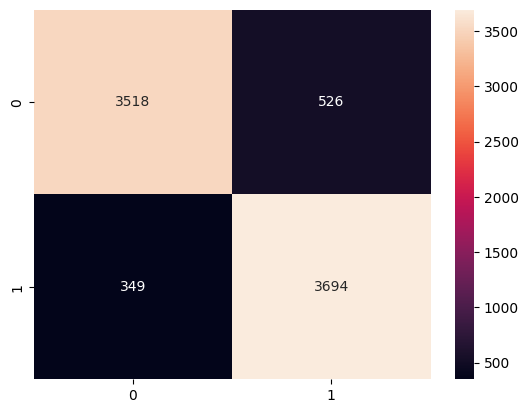

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 3. Pipeline con Word2Vec ---
pipeline = Pipeline([
    # Usamos nuestra clase personalizada en lugar de TfidfVectorizer
    ('w2v', Word2VecTransformer(vector_size=100, min_count=1)),
    ('clf', LogisticRegression(max_iter=100, class_weight='balanced'))
])

# 4. Entrenar
print("Entrenando modelo con Word2Vec...")
pipeline.fit(X_train, y_train)

# 5. Evaluar
predictions = pipeline.predict(X_test)

print("\n--- Reporte de Clasificación (Word2Vec) ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
X = df['text_']
y = df['label']

vectorizer=Word2VecTransformer(vector_size=100, min_count=1)
X_vectorizado = vectorizer.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_vectorizado, y, test_size=0.2, random_state=42,stratify=y) #mejora con stratify=y


# Definir modelo
logreg = LogisticRegression(max_iter=100,class_weight='balanced')

# Hiperparámetros para ajustar
param_grid = {
    'C': [0.01, 0.1, 1, 10],       # regularización inversa
    'penalty': ['l2'],             # L2 regularization
    'solver': ['lbfgs']            # solver compatible
}

# GridSearchCV con validación cruzada
grid = GridSearchCV(logreg, param_grid, cv=5, scoring='roc_auc')
grid.fit(X_train, y_train)

# Mejor modelo
best_logreg = grid.best_estimator_

              precision    recall  f1-score   support

           0       0.90      0.90      0.90      4044
           1       0.90      0.90      0.90      4043

    accuracy                           0.90      8087
   macro avg       0.90      0.90      0.90      8087
weighted avg       0.90      0.90      0.90      8087

ROC-AUC: 0.9541218987868544


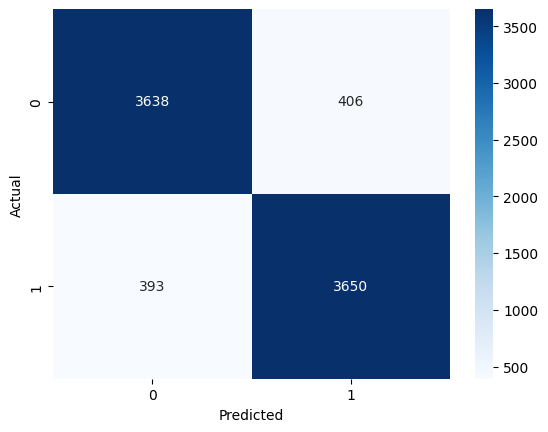

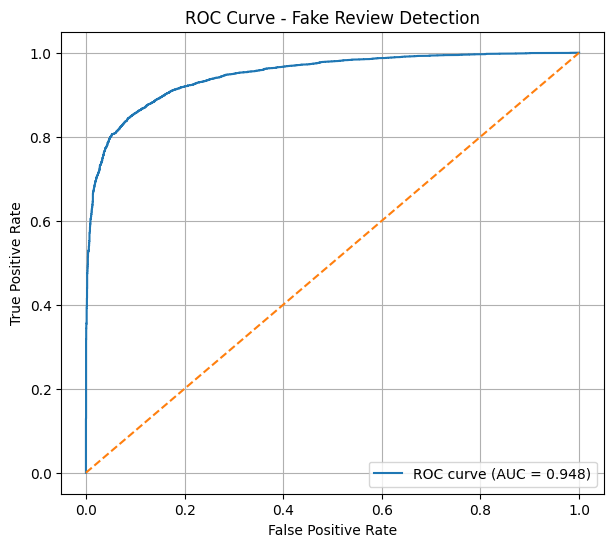

In [ ]:
y_pred = best_logreg.predict(X_test)
y_prob = best_logreg.predict_proba(X_test)[:,1]

# Métricas
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
# Matriz de confusión
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Calcular curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Área bajo la curva
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Fake Review Detection')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

OPCIÓN 3 (SVM): TF-IDF (que tiene muchas dimensiones, ej. 15,000) funciona mejor con modelos lineales (LinearSVC), mientras que Word2Vec (que tiene pocas dimensiones, ej. 100, pero muy densas) se beneficia más de modelos no lineales (SVC normal)

Entrenando modelo con Word2Vec...


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(



--- Reporte de Clasificación (Word2Vec) ---
              precision    recall  f1-score   support

           0       0.93      0.90      0.91      4044
           1       0.90      0.93      0.92      4043

    accuracy                           0.92      8087
   macro avg       0.92      0.92      0.92      8087
weighted avg       0.92      0.92      0.92      8087


--- Matriz de Confusión ---
[[3638  406]
 [ 270 3773]]


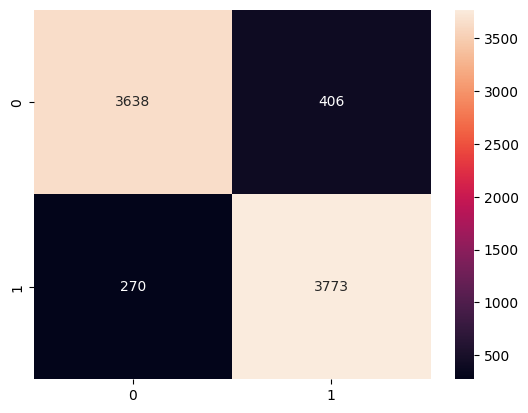

In [23]:
#mejor intento 0.92
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

X = df['text_']
y = df['label']
X_train, X_test_SVM, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


# --- 3. Pipeline con Word2Vec ---
pipeline = Pipeline([
    # Usamos nuestra clase personalizada en lugar de TfidfVectorizer
    ('w2v', Word2VecTransformer(vector_size=200, min_count=1)),
    ('scaler', StandardScaler()),
    ('clf', SVC(class_weight='balanced', random_state=42, max_iter=10000,probability=True, C=10)) #necesita muchas iteraciones,el algoritmo necesita dar más "pasos" para encontrar la frontera de decisión óptima
])

# 4. Entrenar
print("Entrenando modelo con Word2Vec...")
pipeline.fit(X_train, y_train)

# 5. Evaluar
predictions = pipeline.predict(X_test_SVM)

print("\n--- Reporte de Clasificación (Word2Vec) ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()




In [30]:
# Matriz de confusión
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test,predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


              precision  recall  f1-score  support
0                  0.93    0.90      0.91  4044.00
1                  0.90    0.93      0.92  4043.00
accuracy           0.92    0.92      0.92     0.92
macro avg          0.92    0.92      0.92  8087.00
weighted avg       0.92    0.92      0.92  8087.00


In [18]:
from sklearn.model_selection import GridSearchCV

# Definimos el Pipeline (igual que lo tienes)
pipeline = Pipeline([
    ('w2v', Word2VecTransformer(min_count=1)), # Quitamos los valores fijos aquí
    ('scaler', StandardScaler()),
    ('clf', SVC(class_weight='balanced', max_iter=2000))
])

# Definimos qué parámetros probar
param_grid = {
    'w2v__vector_size': [100, 200, 300],  # Probar vectores más grandes
    'w2v__window': [3, 5, 7],             # Contexto de la palabra
    'clf__C': [0.1, 1, 10]
}

print("Buscando los mejores hiperparámetros (esto tardará)...")
grid = GridSearchCV(pipeline, param_grid, cv=3, n_jobs=-1, verbose=2)
grid.fit(X_train, y_train)

print(f"Mejores parámetros: {grid.best_params_}")
print(f"Mejor Accuracy: {grid.best_score_}")

# Evaluar el mejor modelo encontrado
best_model = grid.best_estimator_
predictions = best_model.predict(X_test)

Buscando los mejores hiperparámetros (esto tardará)...
Fitting 3 folds for each of 27 candidates, totalling 81 fits


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Mejores parámetros: {'clf__C': 10, 'w2v__vector_size': 200, 'w2v__window': 5}
Mejor Accuracy: 0.8745711006100311



--- Reporte de Clasificación (Word2Vec) ---
              precision    recall  f1-score   support

           0       0.90      0.91      0.91      4044
           1       0.91      0.90      0.91      4043

    accuracy                           0.91      8087
   macro avg       0.91      0.91      0.91      8087
weighted avg       0.91      0.91      0.91      8087


--- Matriz de Confusión ---
[[3671  373]
 [ 386 3657]]


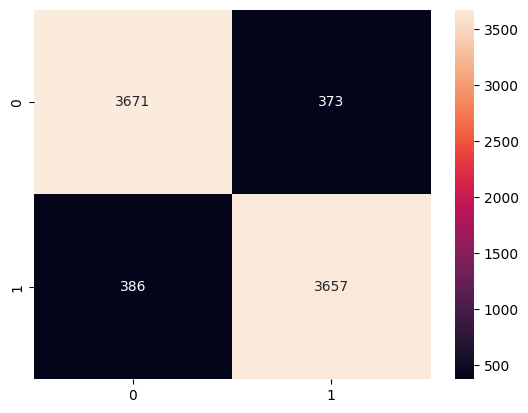

In [11]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
X = df['text_']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipeline = Pipeline([
    # Usamos nuestra clase personalizada en lugar de TfidfVectorizer
    ('tfidf', TfidfVectorizer(stop_words='english', max_df=0.7,ngram_range=(1, 2))),
    ('clf', LinearSVC(class_weight='balanced', random_state=42, max_iter=5000))
])

param_grid_svm = {
    'clf__C': [0.01, 0.1, 1, 10]
}
grid_svm = GridSearchCV(
    pipeline,
    param_grid_svm,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
# 4. Entrenar
grid_svm.fit(X_train, y_train)
best_svm = grid_svm.best_estimator_
# 5. Evaluar
predictions = best_svm.predict(X_test)

print("\n--- Reporte de Clasificación (Word2Vec) ---")
print(classification_report(y_test, predictions))

print("\n--- Matriz de Confusión ---")
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)
print(cm)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

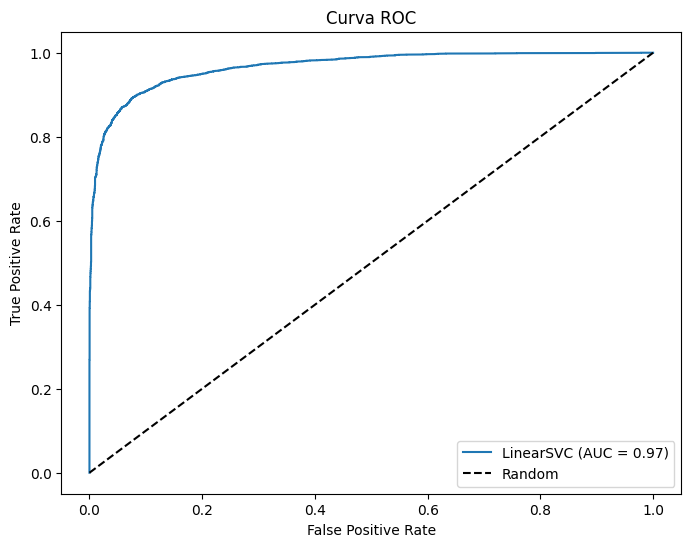

In [20]:
y_scores = best_svm.decision_function(X_test)
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'LinearSVC (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.show()

In [16]:
print(f"Mejores parámetros: {grid_svm.best_params_}")
print(f"Mejor Accuracy: {grid_svm.best_score_}")

Mejores parámetros: {'clf__C': 10}
Mejor Accuracy: 0.8977730487235931


Para notar una mayor mejoría es necesario pasar a Deep Learning (LSTM o CNN)

OPCIÓN 4 (Tensorflow): LSTM

In [3]:
def preparar_datos(texts, labels, num_words, max_len):
    tokenizer = Tokenizer(num_words=num_words, oov_token="<OOV>")
    tokenizer.fit_on_texts(texts)

    sequences = tokenizer.texts_to_sequences(texts)

    # IMPORTANTE: Usar padding y truncating iguales
    padded = pad_sequences(sequences, maxlen=max_len, padding='pre', truncating='post')

    word_index = tokenizer.word_index
    # El tamaño del vocabulario es el mínimo entre tu límite y las palabras reales + 1 (por el padding 0)
    vocab_size = min(num_words, len(word_index) + 1)

    return padded, np.array(labels), tokenizer, vocab_size

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 41s 39ms/step - accuracy: 0.8072 - loss: 0.3773 - precision: 0.7938 - val_accuracy: 0.9066 - val_loss: 0.2435 - val_precision: 0.9244
Epoch 2/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.9487 - loss: 0.1419 - precision: 0.9484 - val_accuracy: 0.8927 - val_loss: 0.2600 - val_precision: 0.8656
Epoch 3/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.9585 - loss: 0.1214 - precision: 0.9592 - val_accuracy: 0.9306 - val_loss: 0.1904 - val_precision: 0.9386
Epoch 4/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.9757 - loss: 0.0739 - precision: 0.9773 - val_accuracy: 0.9432 - val_loss: 0.1833 - val_precision: 0.9473
Epoch 5/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.9842 - loss: 0.0487 - precision: 0.9868 - val_accuracy: 0.9419 - val_loss: 0.2111 - val_precision: 0.9594
Epoch 6/10
759/759 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.9903 - loss: 0.0321 - precision: 0.9916 - val_accuracy: 0.9418

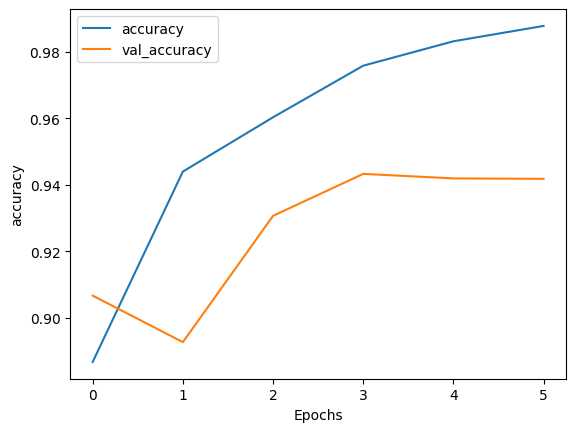

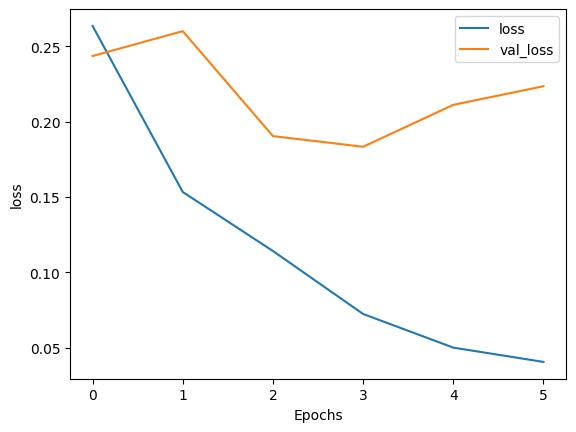

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step

--- Predicciones ---
Texto: This product is amazing I love it very much good quality.
Probabilidad: 0.4180
Texto: Honestly, the box arrived crushed but the product inside was surprisingly intact.
Probabilidad: 0.5894
253/253 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4044
           1       0.95      0.94      0.95      4043

    accuracy                           0.95      8087
   macro avg       0.95      0.95      0.95      8087
weighted avg       0.95      0.95      0.95      8087


--- Matriz de Confusión ---
[[3852  192]
 [ 244 3799]]


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D, Dropout, Bidirectional

num_words= 10000      # Número máximo de palabras a recordar (más repetidas)
max_len = 200        # Cortamos reviews a n palabras (para uniformidad)
EMBEDDING_DIM = 64    # Dimensión del vector (16 es poco para 10k palabras)


texts = df["text_"].astype(str).to_list() # .astype(str) evita errores con nulos
labels = df["label"].to_list()

X, y, tokenizer, vocab_size = preparar_datos(texts, labels, num_words=num_words, max_len=max_len)


# 4. Dividir en entrenamiento y prueba
temp_sentences, test_sentences, temp_labels, test_labels = train_test_split(
    X, y , test_size=0.2, random_state=42, stratify=y
)
#dividir temp en train y val
train_sentences, val_sentences, train_labels, val_labels = train_test_split(
    temp_sentences, temp_labels, test_size=0.25, random_state=42, stratify=temp_labels
)


# 7. Definir el Modelo
model = Sequential([

    Embedding(num_words, EMBEDDING_DIM, input_length=max_len),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(64)),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Compilar
model.compile(loss='binary_crossentropy',optimizer='adam', metrics=['accuracy'])

# Resumen
model.summary()


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_sentences,
    np.array(train_labels),
    epochs=10,             # puedes poner muchos
    validation_data=(val_sentences, np.array(val_labels)),
    callbacks=[early_stop],
    verbose=1
)




In [ ]:
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# --- MEJORA 1: Configuración más robusta ---
num_words = 20000       # Capturamos más palabras
EMBEDDING_DIM = 128     # Vectores con más definición
max_len = 200

texts = df["text_"].astype(str).to_list() # .astype(str) evita errores con nulos
labels = df["label"].to_list()

X, y, tokenizer, vocab_size = preparar_datos(texts, labels, num_words=num_words, max_len=max_len)
# 4. Dividir en entrenamiento y prueba
temp_sentences, test_sentences, temp_labels, test_labels = train_test_split(
    X, y , test_size=0.2, random_state=42, stratify=y
)
#dividir temp en train y val
train_sentences, val_sentences, train_labels, val_labels = train_test_split(
    temp_sentences, temp_labels, test_size=0.25, random_state=42, stratify=temp_labels
)

# --- MEJORA 2: Arquitectura con Regularización ---
model = Sequential([
    Embedding(num_words, EMBEDDING_DIM, input_length=max_len),

    # Dropout espacial elimina canales enteros del embedding (fuerza independencia)
    SpatialDropout1D(0.3),

    # Añadimos regularización L2 (kernel_regularizer) para evitar overfitting
    Bidirectional(LSTM(64, return_sequences=False, kernel_regularizer=l2(0.001))),

    Dense(32, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])



model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# --- MEJORA 3: Callbacks Avanzados ---
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,             # Damos un poco más de margen
    restore_best_weights=True
)

# Si el error no baja en 2 épocas, reducimos el learning rate a la mitad
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

print("Entrenando modelo optimizado...")
history = model.fit(
    train_sentences,
    np.array(train_labels),
    epochs=20,              # Subimos epochs porque ReduceLROnPlateau necesita tiempo
    batch_size=64,          # 64 suele ser más estable que 32
    validation_data=(val_sentences, np.array(val_labels)),
    callbacks=[early_stop, reduce_lr], # Añadimos ambos callbacks
    verbose=1
)



Entrenando modelo optimizado...
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


380/380 ━━━━━━━━━━━━━━━━━━━━ 13s 25ms/step - accuracy: 0.7699 - loss: 0.5990 - val_accuracy: 0.9185 - val_loss: 0.2477 - learning_rate: 0.0010
Epoch 2/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9232 - loss: 0.2558 - val_accuracy: 0.9335 - val_loss: 0.2104 - learning_rate: 0.0010
Epoch 3/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9567 - loss: 0.1642 - val_accuracy: 0.9389 - val_loss: 0.1946 - learning_rate: 0.0010
Epoch 4/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9669 - loss: 0.1323 - val_accuracy: 0.9368 - val_loss: 0.1984 - learning_rate: 0.0010
Epoch 5/20
379/380 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9753 - loss: 0.0992
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
380/380 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9753 - loss: 0.0992 - val_accuracy: 0.9282 - val_loss: 0.2470 - learning_rate: 0.0010
Epoch 6/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9782 - loss: 0.0892 - val_

Vocabulario aprendido: 39039 palabras
Forma de los datos de entrenamiento: (32345, 120)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_26 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_26                │ ?                      │   0 (unbuilt) │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 17s 15ms/step - accuracy: 0.8338 - loss: 0.3520 - val_accuracy: 0.9384 - val_loss: 0.1578
Epoch 2/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 36s 36ms/step - accuracy: 0.9502 - loss: 0.1327 - val_accuracy: 0.9335 - val_loss: 0.2028
Epoch 3/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.9605 - loss: 0.1061 - val_accuracy: 0.9424 - val_loss: 0.1607
Epoch 4/5
1011/1011 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9709 - loss: 0.0797 - val_accuracy: 0.9499 - val_loss: 0.1636


In [ ]:
# NO MEJORA
from tensorflow.keras.layers import Conv1D, MaxPooling1D

# Configuración
num_words = 20000
max_len = 200
EMBEDDING_DIM = 128

model_cnn_lstm = Sequential([

    Embedding(num_words, EMBEDDING_DIM, input_length=max_len),
    SpatialDropout1D(0.3),

    # Conv1D: Escanea ventanas de 5 palabras (kernel_size=5)
    # filters=64: Busca 64 tipos de patrones distintos
    Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),

    # MaxPooling1D: Se queda con el patrón más fuerte de cada grupo de 4
    # Esto reduce el tamaño de la secuencia de 200 a 50. ¡Mucho más rápido para la LSTM!
    MaxPooling1D(pool_size=4),
    Bidirectional(LSTM(64)),

    # 4. Capas finales (iguales)
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Compilar
model_cnn_lstm.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

model_cnn_lstm.summary()
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,             # Damos un poco más de margen
    restore_best_weights=True
)

# Si el error no baja en 2 épocas, reducimos el learning rate a la mitad
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

print("Entrenando modelo optimizado...")
history = model_cnn_lstm.fit(
    train_sentences,
    np.array(train_labels),
    epochs=20,              # Subimos epochs porque ReduceLROnPlateau necesita tiempo
    batch_size=64,          # 64 suele ser más estable que 32
    validation_data=(val_sentences, np.array(val_labels)),
    callbacks=[early_stop, reduce_lr], # Añadimos ambos callbacks
    verbose=1
)

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_23 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_23            │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_23                │ ?                      │   0 (unbuilt) │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Entrenando modelo optimizado...
Epoch 1/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.7795 - loss: 0.4198 - val_accuracy: 0.9264 - val_loss: 0.1827 - learning_rate: 0.0010
Epoch 2/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9545 - loss: 0.1289 - val_accuracy: 0.9284 - val_loss: 0.1899 - learning_rate: 0.0010
Epoch 3/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9744 - loss: 0.0748 - val_accuracy: 0.9409 - val_loss: 0.1683 - learning_rate: 0.0010
Epoch 4/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9821 - loss: 0.0500 - val_accuracy: 0.9426 - val_loss: 0.2025 - learning_rate: 0.0010
Epoch 5/20
378/380 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9912 - loss: 0.0292
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
380/380 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9911 - loss: 0.0293 - val_accuracy: 0.9444 - val_loss: 0.2023 - learning_rate: 0.0010
Epoch 6/20
380/380 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/st

In [ ]:
# 10. Gráfica de precisión
def plot_graphs(history, string):
  plt.plot(history.history[string])
  plt.plot(history.history['val_'+string])
  plt.xlabel("Epochs")
  plt.ylabel(string)
  plt.legend([string, 'val_'+string])
  plt.show()

plot_graphs(history, "accuracy")
plot_graphs(history, "loss")

# 11. Probando con una frase nueva
new_reviews = [
    "This product is amazing I love it very much good quality.", # Ejemplo 'Bot-like' simple
    "Honestly, the box arrived crushed but the product inside was surprisingly intact." # Ejemplo 'Humano'
]

# Preprocesar las nuevas frases igual que las de entrenamiento
new_sequences = tokenizer.texts_to_sequences(new_reviews)
new_padded = pad_sequences(new_sequences, maxlen=max_len, truncating='post')

predictions = model.predict(new_padded)

# Decodificar resultados
print("\n--- Predicciones ---")
for i, text in enumerate(new_reviews):
    print(f"Texto: {text}")
    print(f"Probabilidad: {predictions[i][0]:.4f}")

# 1. Obtener predicciones del modelo
y_pred_probs = model.predict(test_sentences)

# 2. Convertir probabilidades a clases (0 o 1)
y_pred = (y_pred_probs > 0.5).astype(int)

# 3. Reporte de clasificación
print("\n--- Reporte de Clasificación ---")
print(classification_report(test_labels, y_pred))

# 4. Matriz de confusión
print("\n--- Matriz de Confusión ---")
print(confusion_matrix(test_labels, y_pred))

Output hidden; open in https://colab.research.google.com to view.

COMBINACIÓN

In [ ]:
# 1. Predicciones del modelo LSTM
probs_lstm = model.predict(test_sentences)
# 2. Predicciones del modelo SVM (asegúrate de usar probability=True si usas SVC)
# O usa decision_function y pásalo a sigmoide
probs_svm = pipeline.predict_proba(X_test_SVM)[:, 1] # Asumiendo que es la clase 1

# 3. Promedio (Ensemble)
probs_ensemble = (probs_lstm.flatten() + probs_svm) / 2

# 4. Decisión final
preds_ensemble = (probs_ensemble > 0.5).astype(int)

print("--- Accuracy del Ensemble ---")
print(classification_report(y_test, preds_ensemble))
print(confusion_matrix(y_test, preds_ensemble))

253/253 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step
--- Accuracy del Ensemble ---
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4044
           1       0.95      0.95      0.95      4043

    accuracy                           0.95      8087
   macro avg       0.95      0.95      0.95      8087
weighted avg       0.95      0.95      0.95      8087

[[3850  194]
 [ 212 3831]]


In [ ]:
def predecir_con_ensamble(frases_nuevas):
    """
    Recibe una lista de frases y devuelve la predicción combinada.
    """
    # --- 1. PREPARAR DATOS PARA SVM ---
    # El pipeline de SVM acepta texto crudo directamente
    # Obtenemos la probabilidad de la clase 1 (Fake o la que sea tu clase positiva)
    probs_svm = pipeline.predict_proba(frases_nuevas)[:, 1]

    # --- 2. PREPARAR DATOS PARA LSTM ---
    # El LSTM necesita secuencias numéricas y padding
    secuencias = tokenizer.texts_to_sequences(frases_nuevas)
    # Importante: usar el mismo max_len que en el entrenamiento
    padded = pad_sequences(secuencias, maxlen=max_len)

    # Obtenemos predicción (devuelve lista de listas, hacemos flatten para tener array simple)
    probs_lstm = model.predict(padded).flatten()

    # --- 3. COMBINAR (ENSAMBLE) ---
    # Promedio simple
    probs_finales = (probs_svm + probs_lstm) / 2

    # Decisión final (Umbral 0.5)
    predicciones_clase = (probs_finales > 0.5).astype(int)

    return probs_svm, probs_lstm, probs_finales, predicciones_clase

# =========================================
# EJEMPLO DE USO
# =========================================

# Lista de frases nuevas para probar
nuevas_reviews = [
    "I absolutely love this product, the quality is amazing and shipping was fast.", # Parece Real
    "Do not buy this garbage. The box was empty and customer service is a scam.",    # Parece Fake/Negativa
    "Excellent item, very useful for my daily routine."                             # Ambiguo
]

# Llamamos a la función
p_svm, p_lstm, p_final, clases = predecir_con_ensamble(nuevas_reviews)

# Mostramos los resultados bonitos
print("\n--- RESULTADOS DEL ENSAMBLE ---")
for i, texto in enumerate(nuevas_reviews):
    print(f"\nTexto: '{texto}'")
    print(f"   - Confianza SVM:  {p_svm[i]:.4f}")
    print(f"   - Confianza LSTM: {p_lstm[i]:.4f}")
    print(f"   -> PROMEDIO:      {p_final[i]:.4f}")

    # Si usaste LabelEncoder al principio, puedes decodificarlo así:
    # etiqueta = le.inverse_transform([clases[i]])[0]
    # O manual si sabes que 0=Real y 1=Fake:
    etiqueta = "CLASE 1 (Fake)" if clases[i] == 1 else "CLASE 0 (Real)"

    print(f"   -> PREDICCIÓN:    {etiqueta}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step

--- RESULTADOS DEL ENSAMBLE ---

Texto: 'I absolutely love this product, the quality is amazing and shipping was fast.'
   - Confianza SVM:  0.2734
   - Confianza LSTM: 0.7022
   -> PROMEDIO:      0.4878
   -> PREDICCIÓN:    CLASE 0 (Real)

Texto: 'Do not buy this garbage. The box was empty and customer service is a scam.'
   - Confianza SVM:  0.0613
   - Confianza LSTM: 0.1458
   -> PROMEDIO:      0.1035
   -> PREDICCIÓN:    CLASE 0 (Real)

Texto: 'Excellent item, very useful for my daily routine.'
   - Confianza SVM:  0.1989
   - Confianza LSTM: 0.0297
   -> PROMEDIO:      0.1143
   -> PREDICCIÓN:    CLASE 0 (Real)
